In [ ]:
# VGG provenance: tf.keras.applications.VGG16, include_top=False; ImageNet weights ported by Keras Applications; CC BY 4.0. Base frozen, new GAP/Dense(128)/Dropout(0.4)/Dense(3) head trained; no fine-tuning.
# ResNet provenance: tf.keras.applications.ResNet50 (v1), include_top=False; ImageNet weights ported by Keras Applications; MIT. Base frozen, new GAP/Dense(128)/Dropout(0.4)/Dense(3) head trained; no fine-tuning.
# Data/training: AI-Lab-Makerere/beans (source: as stated in notebook or unverified), 224x224 RGB, official 1,034/133/128 train/validation/test splits, each model's preprocess_input inside its model.
# Both: Adam lr=0.0001, sparse categorical crossentropy, accuracy, batch 16, up to 10 epochs, EarlyStopping on validation loss (patience 3, restore best weights).

In [1]:
%pip install -U tensorflow tensorflow-datasets scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print("GPU configuration message:", e)

if gpus:
    print("NVIDIA GPU is available to TensorFlow.")
else:
    print("No GPU detected. Training will use the CPU unless GPU support is configured.")

I0000 00:00:1791790897.666141    1112 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791790897.714408    1112 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791790907.729829    1112 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:2', device_type='GPU')]
NVIDIA GPU is available to TensorFlow.


W0000 00:00:1791790917.194698    1112 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1791790917.212567    1112 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1791790917.232219    1112 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [3]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, ResNet50

from tensorflow.keras.applications.vgg16 import (
    preprocess_input as vgg_preprocess
)

from tensorflow.keras.applications.resnet50 import (
    preprocess_input as resnet_preprocess
)

from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [4]:
%pip install importlib_resources

Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install -U datasets

Note: you may need to restart the kernel to use updated packages.


In [6]:
from datasets import load_dataset

beans = load_dataset("AI-Lab-Makerere/beans")

print(beans)
print(beans["train"].features)

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
{'image_file_path': Value('string'), 'image': Image(mode=None, decode=True), 'labels': ClassLabel(names=['angular_leaf_spot', 'bean_rust', 'healthy'])}


In [7]:
import tensorflow as tf
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 16

class_names = beans["train"].features["labels"].names
num_classes = len(class_names)

print("Classes:", class_names)

def convert_split(split, training=False):
    images = np.stack([
        np.array(item.convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        for item in split["image"]
    ]).astype("float32")

    labels = np.array(split["labels"], dtype="int32")

    ds = tf.data.Dataset.from_tensor_slices((images, labels))

    if training:
        ds = ds.shuffle(len(labels), seed=42)

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = convert_split(beans["train"], training=True)
val_ds = convert_split(beans["validation"])
test_ds = convert_split(beans["test"])

print("Dataset loaded successfully.")

Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']


W0000 00:00:1791791035.815914    1112 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1791791035.844899    1112 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1791791035.863780    1112 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1791791036.026053    1112 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 180218 MB memory:  -> device: 0, name: NVIDIA B200, pci bus id: 0000:1b:00.0, compute capability: 10.0a
I0000 00:00:1791791036.043589    1112 gpu_device.cc:2043] Created devic

Dataset loaded successfully.


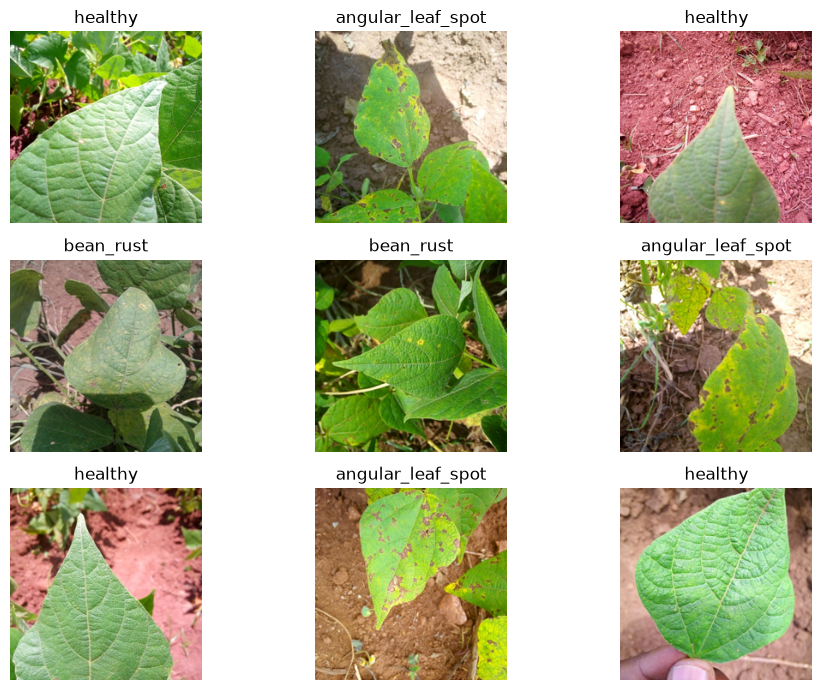

In [9]:
plt.figure(figsize=(10, 7))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
vgg_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg_base.trainable = False

print("Pretrained VGG16 loaded.")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Pretrained VGG16 loaded.


In [11]:
vgg_input = layers.Input(shape=(224, 224, 3))

# Preprocessing required by VGG16
x = layers.Lambda(vgg_preprocess)(vgg_input)

# Pretrained feature extractor
x = vgg_base(x, training=False)

# New classifier for three bean classes
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)
vgg_output = layers.Dense(num_classes, activation="softmax")(x)

vgg_model = models.Model(
    inputs=vgg_input,
    outputs=vgg_output,
    name="Beans_VGG16"
)

vgg_model.summary()

Model: "Beans_VGG16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,739 (56.38 MB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [12]:
vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [13]:
early_stop_vgg = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

vgg_history = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop_vgg]
)

Epoch 1/10


<runtime-home>/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791791408.335283    1937 service.cc:153] XLA service 0x721c64047310 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791791408.335305    1937 service.cc:161]   StreamExecutor [0]: NVIDIA B200, Compute Capability 10.0a (Driver: 12.9.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.10.2)
I0000 00:00:1791791408.335315    1937 service.cc:161]   StreamExecutor [1]: NVIDIA B200, Compute Capability 10.0a (Driver: 12.9.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.10.2)
I0000 00:00:1791791408.335317    1937 service.cc:161]   StreamExecutor [2]: NVIDIA B200, Compute Capability 10.0a (Driver: 12.9.0; Runtim

33/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3674 - loss: 4.7602

I0000 00:00:1791791412.911799    1937 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


54/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3924 - loss: 4.0832

I0000 00:00:1791791413.474581    1937 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2035__.67


65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.3926 - loss: 3.8668

I0000 00:00:1791791418.876258    4254 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_4', 8 bytes spill stores, 8 bytes spill loads



65/65 ━━━━━━━━━━━━━━━━━━━━ 14s 127ms/step - accuracy: 0.3926 - loss: 3.8668 - val_accuracy: 0.4737 - val_loss: 1.6851
Epoch 2/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4952 - loss: 2.4857 - val_accuracy: 0.6316 - val_loss: 1.1144
Epoch 3/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5716 - loss: 1.8655 - val_accuracy: 0.6842 - val_loss: 0.8277
Epoch 4/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6509 - loss: 1.2967 - val_accuracy: 0.7594 - val_loss: 0.6850
Epoch 5/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6557 - loss: 1.1790 - val_accuracy: 0.7820 - val_loss: 0.6225
Epoch 6/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7012 - loss: 0.9235 - val_accuracy: 0.7970 - val_loss: 0.5752
Epoch 7/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7186 - loss: 0.8592 - val_accuracy: 0.8045 - val_loss: 0.5239
Epoch 8/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7331 - loss: 0.7520 - val_accuracy: 0.8271 - val_loss: 0.4968


In [14]:
vgg_loss, vgg_accuracy = vgg_model.evaluate(test_ds, verbose=1)

print("VGG16 Test Loss:", round(vgg_loss, 4))
print("VGG16 Test Accuracy:", round(vgg_accuracy * 100, 2), "%")

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8438 - loss: 0.4315 
VGG16 Test Loss: 0.4315
VGG16 Test Accuracy: 84.38 %


In [15]:
resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

resnet_base.trainable = False

print("Pretrained ResNet50 loaded.")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
Pretrained ResNet50 loaded.


In [16]:
resnet_input = layers.Input(shape=(224, 224, 3))

# Preprocessing required by ResNet50
x = layers.Lambda(resnet_preprocess)(resnet_input)

# Pretrained feature extractor
x = resnet_base(x, training=False)

# New classifier
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)
resnet_output = layers.Dense(num_classes, activation="softmax")(x)

resnet_model = models.Model(
    inputs=resnet_input,
    outputs=resnet_output,
    name="Beans_ResNet50"
)

resnet_model.summary()

Model: "Beans_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [17]:
resnet_input = layers.Input(shape=(224, 224, 3))

# Preprocessing required by ResNet50
x = layers.Lambda(resnet_preprocess)(resnet_input)

# Pretrained feature extractor
x = resnet_base(x, training=False)

# New classifier
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)
resnet_output = layers.Dense(num_classes, activation="softmax")(x)

resnet_model = models.Model(
    inputs=resnet_input,
    outputs=resnet_output,
    name="Beans_ResNet50"
)

resnet_model.summary()

Model: "Beans_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [18]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
early_stop_resnet = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

resnet_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop_resnet]
)

Epoch 1/10


<runtime-home>/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791791488.164032    1933 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_17446__.182


61/65 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6025 - loss: 0.9053

I0000 00:00:1791791493.534161    1937 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_17446__.182


65/65 ━━━━━━━━━━━━━━━━━━━━ 22s 197ms/step - accuracy: 0.6093 - loss: 0.8946 - val_accuracy: 0.8496 - val_loss: 0.4531
Epoch 2/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7901 - loss: 0.5348 - val_accuracy: 0.8872 - val_loss: 0.3407
Epoch 3/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8520 - loss: 0.4025 - val_accuracy: 0.8947 - val_loss: 0.2946
Epoch 4/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8743 - loss: 0.3345 - val_accuracy: 0.9098 - val_loss: 0.2403
Epoch 5/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8917 - loss: 0.2853 - val_accuracy: 0.9323 - val_loss: 0.2119
Epoch 6/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9062 - loss: 0.2552 - val_accuracy: 0.9323 - val_loss: 0.1990
Epoch 7/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9275 - loss: 0.2070 - val_accuracy: 0.9323 - val_loss: 0.1867
Epoch 8/10
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9333 - loss: 0.1938 - val_accuracy: 0.9323 - val_loss: 0.

In [20]:
resnet_loss, resnet_accuracy = resnet_model.evaluate(
    test_ds, verbose=1
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"VGG16 Test Loss:       {vgg_loss:.4f}")
print(f"VGG16 Test Accuracy:   {vgg_accuracy * 100:.2f}%")

print(f"ResNet50 Test Loss:     {resnet_loss:.4f}")
print(f"ResNet50 Test Accuracy: {resnet_accuracy * 100:.2f}%")

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9453 - loss: 0.1735 

========== FINAL TEST RESULTS ==========
VGG16 Test Loss:       0.4315
VGG16 Test Accuracy:   84.38%
ResNet50 Test Loss:     0.1735
ResNet50 Test Accuracy: 94.53%


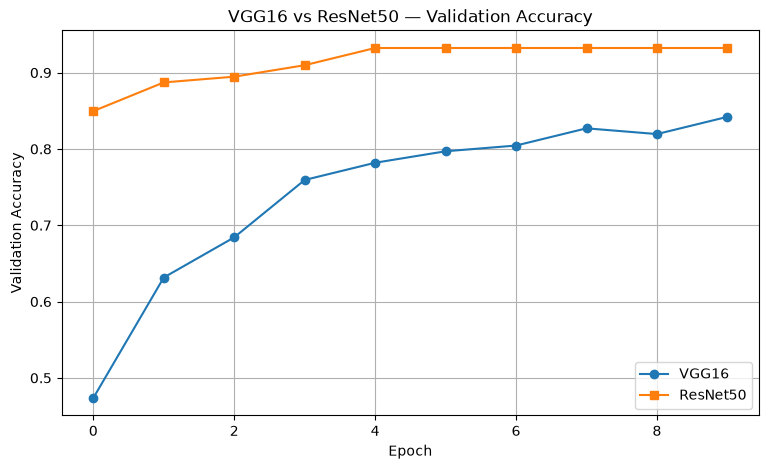

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(
    vgg_history.history["val_accuracy"],
    marker="o",
    label="VGG16"
)

plt.plot(
    resnet_history.history["val_accuracy"],
    marker="s",
    label="ResNet50"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("VGG16 vs ResNet50 — Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


VGG16 Classification Report
                   precision    recall  f1-score   support

angular_leaf_spot       0.77      0.86      0.81        43
        bean_rust       0.84      0.72      0.78        43
          healthy       0.93      0.95      0.94        42

         accuracy                           0.84       128
        macro avg       0.85      0.84      0.84       128
     weighted avg       0.85      0.84      0.84       128



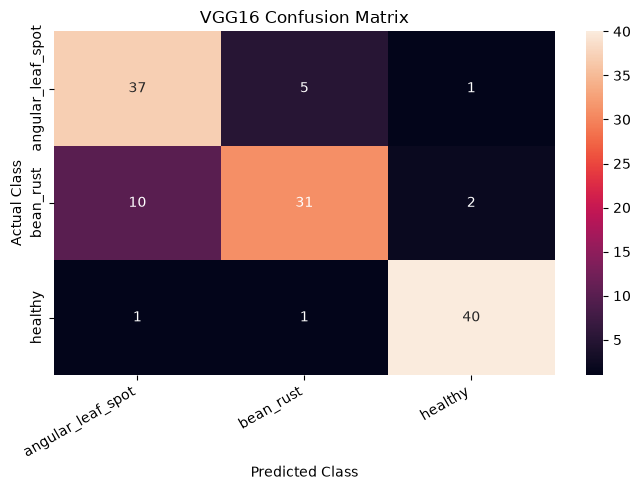


ResNet50 Classification Report
                   precision    recall  f1-score   support

angular_leaf_spot       0.95      0.95      0.95        43
        bean_rust       0.89      0.95      0.92        43
          healthy       1.00      0.93      0.96        42

         accuracy                           0.95       128
        macro avg       0.95      0.95      0.95       128
     weighted avg       0.95      0.95      0.95       128



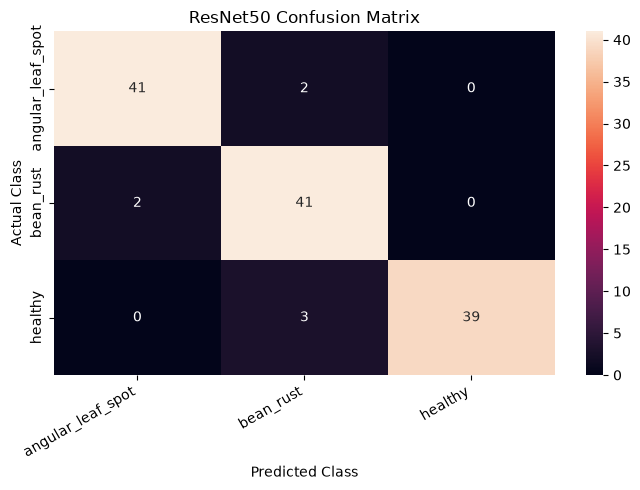

In [22]:
def evaluate_model(model, dataset, model_name):

    y_true = np.concatenate([
        labels.numpy() for _, labels in dataset
    ])

    probabilities = model.predict(dataset, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    print(f"\n{model_name} Classification Report")

    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(num_classes),
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(num_classes)
    )

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


evaluate_model(vgg_model, test_ds, "VGG16")
evaluate_model(resnet_model, test_ds, "ResNet50")

In [23]:
vgg_model.save("beans_vgg16.keras")
resnet_model.save("beans_resnet50.keras")

print("VGG16 saved as beans_vgg16.keras")
print("ResNet50 saved as beans_resnet50.keras")

VGG16 saved as beans_vgg16.keras
ResNet50 saved as beans_resnet50.keras


In [24]:
from tensorflow.keras.utils import load_img, img_to_array

image_path = "bean_leaf.jpg"

img = load_img(image_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

vgg_prob = vgg_model.predict(img_array, verbose=0)[0]
resnet_prob = resnet_model.predict(img_array, verbose=0)[0]

print("VGG16 prediction:", class_names[np.argmax(vgg_prob)])
print("VGG16 probabilities:", np.round(vgg_prob, 3))

print("ResNet50 prediction:", class_names[np.argmax(resnet_prob)])
print("ResNet50 probabilities:", np.round(resnet_prob, 3))

plt.imshow(img)
plt.axis("off")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'bean_leaf.jpg'

In [25]:
import os

print("Current directory:", os.getcwd())
print("Available files:", os.listdir())

Current directory: <runtime-home>
Available files: ['Untitled.ipynb', 'beans_resnet50.keras', 'best_resnet50_cifar10.keras', '.local', '.ipynb_checkpoints', 'cats_dogs', 'best_vgg16_cifar10.keras', 'VGG16_SCR.ipynb', 'beans_vgg16.keras', 'mnist_dense_keras.keras', '01_mnist_keras.ipynb', 'RESNET50.ipynb']


In [26]:
image_path = "bean_leaf.jpg"

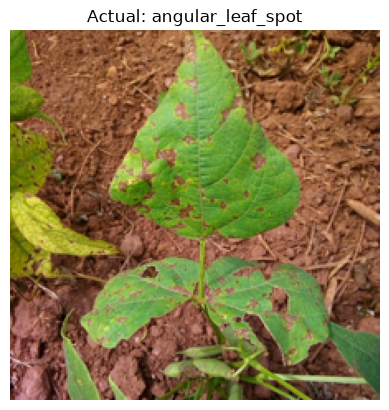

Actual class: angular_leaf_spot
VGG16 prediction: angular_leaf_spot
VGG16 probabilities: [0.905 0.095 0.001]

ResNet50 prediction: angular_leaf_spot
ResNet50 probabilities: [0.75  0.247 0.003]


In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Get one image and label from the test dataset
for images, labels in test_ds.take(1):
    image = images[0]
    actual_label = int(labels[0])

# Add batch dimension
image_array = tf.expand_dims(image, axis=0)

# Predict using both models
vgg_prob = vgg_model.predict(image_array, verbose=0)[0]
resnet_prob = resnet_model.predict(image_array, verbose=0)[0]

# Display image
plt.imshow(image.numpy().astype("uint8"))
plt.axis("off")
plt.title("Actual: " + class_names[actual_label])
plt.show()

# Print predictions
print("Actual class:", class_names[actual_label])
print("VGG16 prediction:", class_names[np.argmax(vgg_prob)])
print("VGG16 probabilities:", np.round(vgg_prob, 3))

print("\nResNet50 prediction:", class_names[np.argmax(resnet_prob)])
print("ResNet50 probabilities:", np.round(resnet_prob, 3))